# Downscaling lab: evaluation

Compares every evaluated run of one experiment against the RCM ground truth and against the published
CORDEX-ML-Bench entries. All heavy computation happens beforehand in `dslab evaluate` (batch job), which
writes small `scores.json` / `diagnostics.nc` files per run and split; this notebook only loads and plots
them, so it runs in about a minute.

| | |
|---|---|
| **Experiment** | set `EXPERIMENT` below (`alps_esd` = ESD pseudo-reality, ALPS; `alps_emulator` also defined) |
| **Splits** | `val` = held-out training years (model selection), `historical_perfect` = Test 1 (1981–2000), `mid_end_century_perfect` = ESD extrapolation as scored by the benchmark (2041–2060 + 2080–2099) |
| **Metric definitions** | `docs/metric_definitions.md`: scorecard metrics reproduce the organisers' code exactly |
| **Producing results** | `sbatch jobs/baselines.sbatch` or `dslab fit / predict / evaluate`, see `README.md` |
| **Resources** | JupyterHub preset *interactive*, 10 GB, kernel **dslab** |

Colours are fixed per run (see `dslab.plotting.run_colors`); the RCM truth is always black, the climatology floor
and published entries grey.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import xarray as xr

from dslab import plotting as P
from dslab import results
from dslab.experiment import Experiment

EXPERIMENT = "alps_esd"
EXP = Experiment.load(EXPERIMENT)
RUNS = results.list_runs(EXP)           # or an explicit list, e.g. ["climatology", "linear"]
SPLIT = "historical_perfect"            # main test split
FUTURE = next(s for s, t in EXP.reference["splits"].items() if t == "lower_right")
# Published entries listed in the tables (the strip plots show all of them)
REF_MODELS = ["DeepESD-IFCAv1-orog", "XGBoost_IDL", "DetUNet-orog", "EnScale-orog",
              "FlowMatching-v1-orog", "UiBCorrDiff-orog", "CorrDiff-TW1_NTNU-CWA-orog"]
FIG_DIR = EXP.eval_dir / "figures"      # None: do not save figures

P.setup_style()
COLORS = P.run_colors(RUNS)
save = (lambda name: FIG_DIR / f"{name}.png") if FIG_DIR else (lambda name: None)
scores = results.load_scores(EXP)
print(EXP.description)
print("runs:", RUNS, "| main split:", SPLIT, "| future split:", FUTURE)

ESD pseudo-reality, ALPS, CNRM-CM5-driven ALADIN63, train 1961-1980
runs: ['climatology', 'linear'] | main split: historical_perfect | future split: mid_end_century_perfect


## 1. Runs
Model, hyperparameters (as selected on the validation years) and fit time.

In [2]:
results.run_info(EXP, RUNS)

,model,params,selected,fit_seconds,fitted,git_commit
run,,,,,,
climatology,climatology,{'window': 31},None,0.4,2026-10-30T14:27:12,unknown
linear,linear,"{'transform': {'pr': 'sqrt'}, 'n_pcs': [50, 10...","{'pr': {'n_pcs': 3840, 'alpha': 10.0, 'val_rms...",54.1,2026-10-30T14:28:58,unknown


## 2. Scorecard against the published entries

The six metrics per variable shown in the benchmark paper (supplement Figs. S12/S13), computed as in the
organisers' code: RMSE of the ensemble mean over all days and grid points; mean bias, SDII, Rx1day, TXx and IAV as
bias maps reduced by the RMS over space; RALSD as the mean squared dB difference of time-mean spectra (dB²);
LHD (dB) and PSS on pooled histograms. Lower is better except PSS. Each grey dot is one published entry
(ALPS domain, with and without orography).

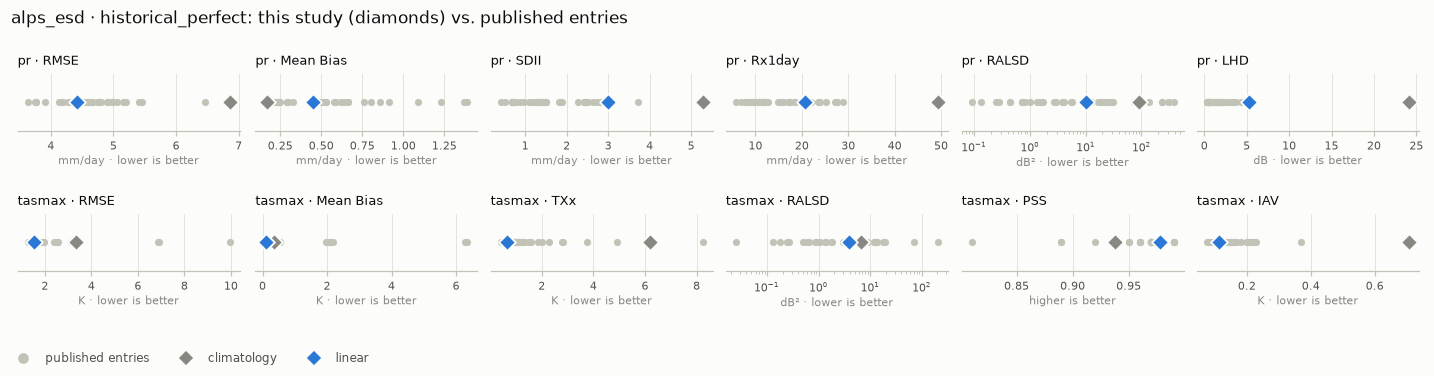

In [3]:
def fmt(v):
    if pd.isna(v):
        return ""
    a = abs(v)
    return f"{v:.3f}" if a < 0.1 else f"{v:.2f}" if a < 10 else f"{v:.1f}" if a < 100 else f"{v:.0f}"


def show_card(card):
    def best(col):
        target = col.max() if col.name[-1] in ("PSS", "Corr (temporal)") else col.abs().min()
        return ["font-weight: 600; background-color: #cde2fb" if pd.notna(v) and abs(v) == abs(target) else ""
                for v in col]
    return card.style.format(fmt).apply(best, axis=0)


card = results.scorecard(EXP, SPLIT, RUNS, scores=scores)
P.fig_scorecard_strips(card, COLORS, title=f"{EXP.name} · {SPLIT}: this study (diamonds) vs. published entries",
                       save=save(f"scorecard_{SPLIT}"));

In [4]:
show_card(results.scorecard(EXP, SPLIT, RUNS, REF_MODELS, scores=scores))

**Future period.** For ESD the benchmark pools 2041–2060 and 2080–2099 (`mid_end_century_perfect`).
Which period the published LHD/PSS values refer to is not determinable from the organisers' code; read those two
with care.

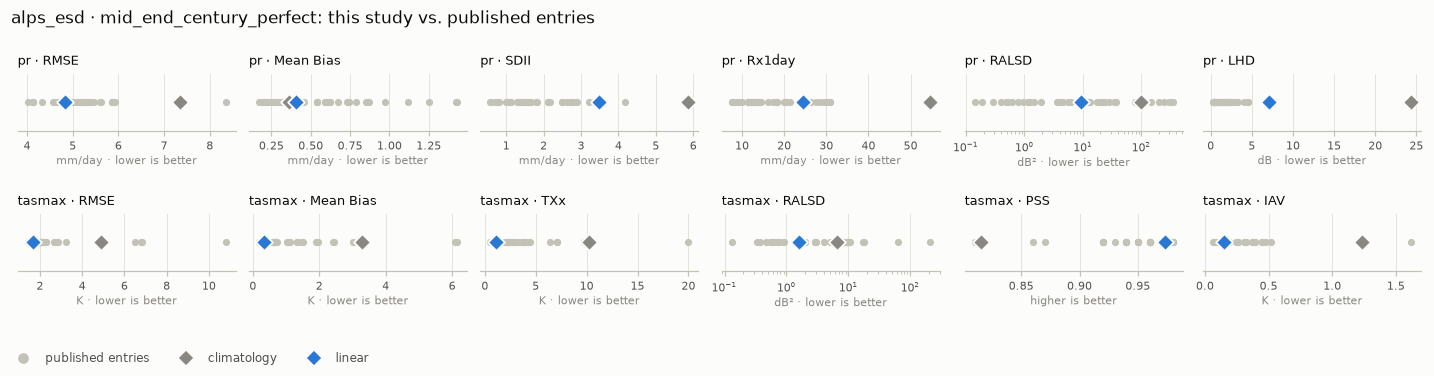

In [5]:
card_f = results.scorecard(EXP, FUTURE, RUNS, scores=scores)
P.fig_scorecard_strips(card_f, COLORS, title=f"{EXP.name} · {FUTURE}: this study vs. published entries",
                       save=save(f"scorecard_{FUTURE}"));
show_card(results.scorecard(EXP, FUTURE, RUNS, REF_MODELS, scores=scores))

## 3. All metrics, all splits

Scorecard metrics plus development diagnostics: MAE, domain-mean bias (signed), mean temporal correlation,
RMS of the 99th-percentile and wet-day-frequency bias maps, CRPS (= MAE for deterministic runs) and, for
ensembles, the spread/skill ratio (≈ 1 when calibrated). `val` is what model selection sees; the test splits
should only be looked at for finished models.

In [6]:
def all_metrics(split):
    s = scores[(scores.split == split) & scores.run.isin(RUNS)]
    wide = s.pivot_table(index="run", columns=["variable", "metric"], values="value", sort=False)
    return wide.reindex(RUNS)

for split in ["val", SPLIT, FUTURE]:
    display(pd.io.formats.style.Styler(all_metrics(split)).format(fmt).set_caption(split))

## 4. Maps on the test period

Top row: RCM truth. Other rows: bias of each run (prediction − truth), shared colour scale per column.
Precipitation: blue = too wet, red = too dry. Temperature: red = too warm, blue = too cold. Indices: Rx1day/TXx =
mean annual maximum, SDII = mean intensity on wet days (≥ 1 mm/day), IAV = standard deviation of annual means.

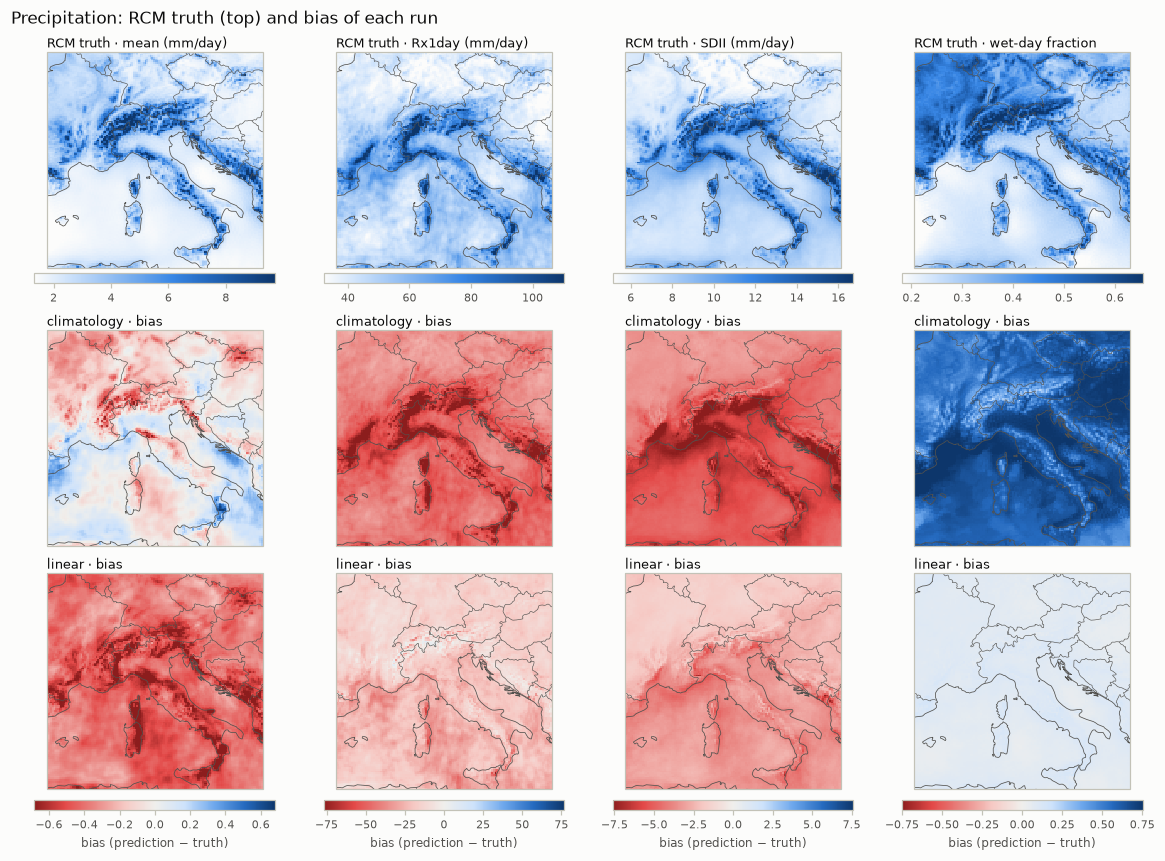

In [7]:
D = {r: results.load_diagnostics(EXP, r, SPLIT) for r in RUNS}
MG = P.MapGrid.from_experiment(EXP, D[RUNS[0]])   # target grid in its own (Lambert) projection
P.fig_bias_maps(D, "pr", [("mean", "mean (mm/day)"), ("Rx1day", "Rx1day (mm/day)"),
                          ("SDII", "SDII (mm/day)"), ("wetfrac", "wet-day fraction")], MG,
                save=save(f"maps_pr_{SPLIT}"));

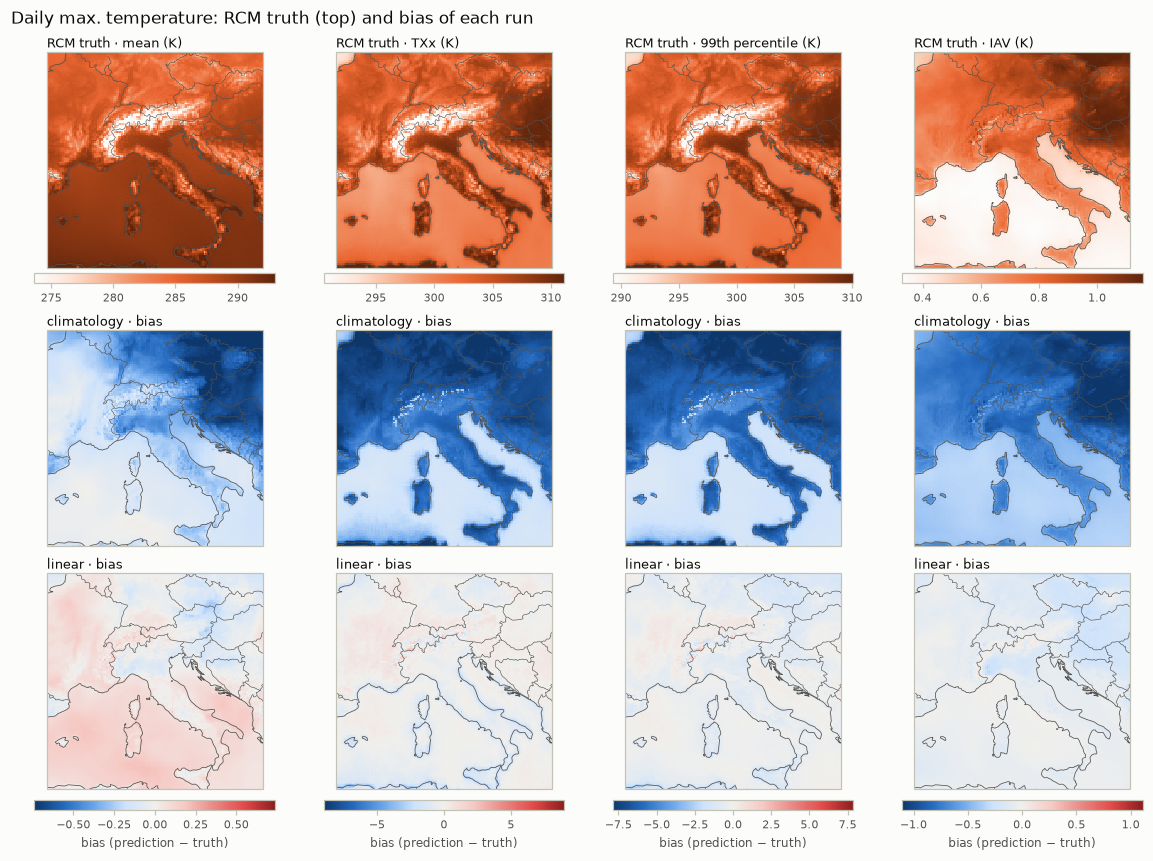

In [8]:
P.fig_bias_maps(D, "tasmax", [("mean", "mean (K)"), ("TXx", "TXx (K)"),
                              ("p99", "99th percentile (K)"), ("IAV", "IAV (K)")], MG,
                save=save(f"maps_tasmax_{SPLIT}"));

Day-to-day skill: RMSE and temporal correlation at every grid point (ensemble mean for stochastic runs).

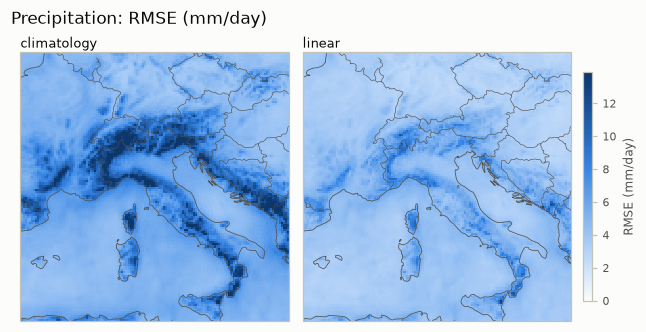

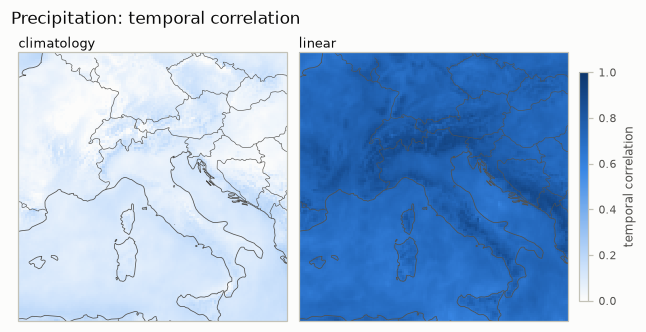

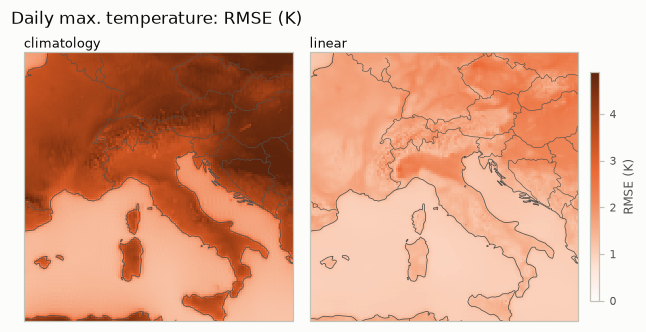

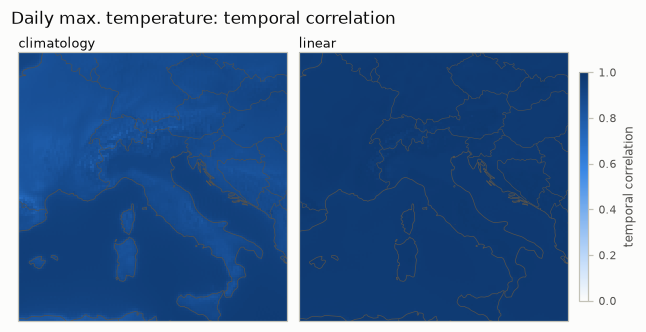

In [9]:
for var in EXP.variables:
    P.fig_field_maps(D, var, "rmse_map", f"RMSE ({P.UNITS[var]})", MG, cmap=P.SEQ[var], vmin=0,
                     save=save(f"rmse_{var}_{SPLIT}"))
    P.fig_field_maps(D, var, "corr_map", "temporal correlation", MG, cmap=P.SEQ["pr"], vmin=0, vmax=1,
                     save=save(f"corr_{var}_{SPLIT}"))

## 5. Example days

The wettest winter (DJF) day, the wettest summer (JJA) day and the hottest day of the test period (domain means of
the truth).
Deterministic models show the conditional mean, so they are expected to look smoother than the truth; a generative
model should look like a plausible weather map, not necessarily like this particular one.

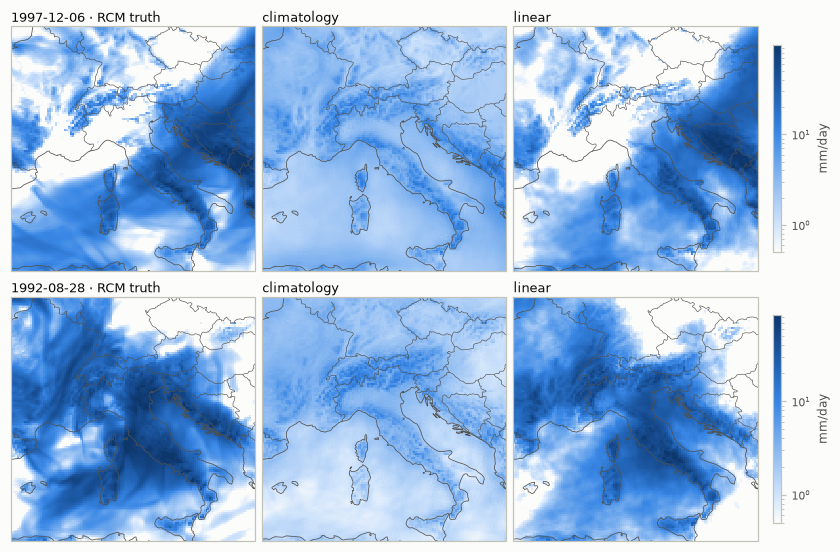

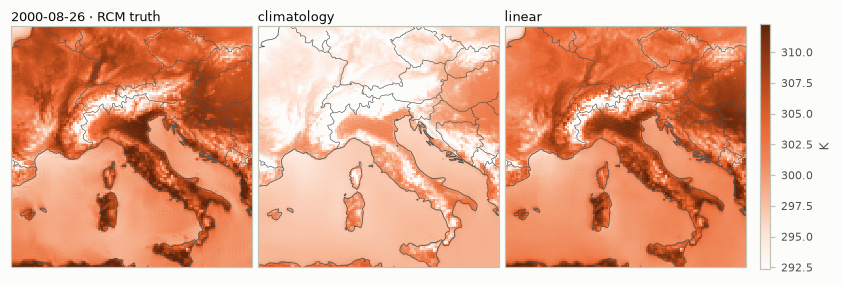

In [10]:
d0 = D[RUNS[0]]
time = pd.DatetimeIndex(d0["time"].values)
pr_dm, tx_dm = d0["pr_series_true"].values, d0["tasmax_series_true"].values
djf, jja = time.month.isin([12, 1, 2]), time.month.isin([6, 7, 8])
dates = [time[djf][np.argmax(pr_dm[djf])], time[jja][np.argmax(pr_dm[jja])], time[np.argmax(tx_dm)]]
for var, days in [("pr", dates[:2]), ("tasmax", dates[2:])]:
    truth = results.load_fields(EXP, SPLIT, days, var)
    preds = {r: results.load_fields(EXP, SPLIT, days, var, run=r) for r in RUNS}
    P.fig_example_days(truth, preds, days, var, MG, save=save(f"days_{var}_{SPLIT}"))

## 6. Spatial structure: power spectra

Mean radially averaged power spectrum of the daily fields (one member), shown up to the Nyquist wavelength
(25 km). The right panel is the ratio to the truth in dB; the published RALSD is the mean square of this curve
over all wavenumber bins. Values below 0 dB at short wavelengths mean the fields are too smooth.

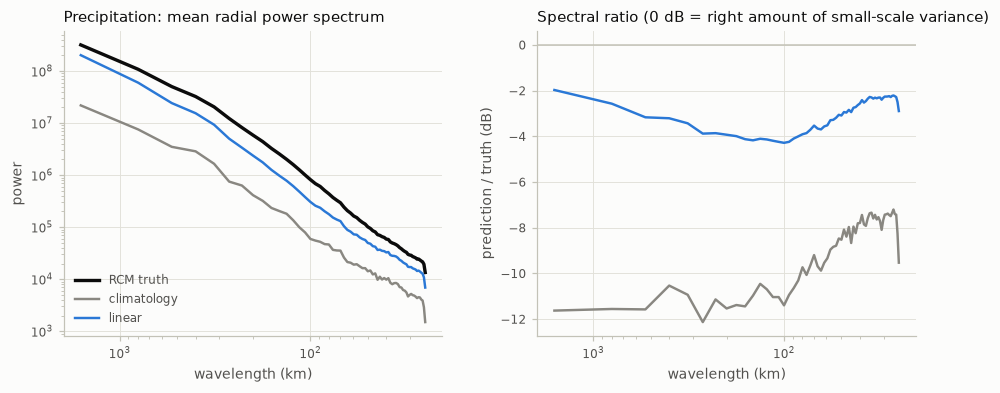

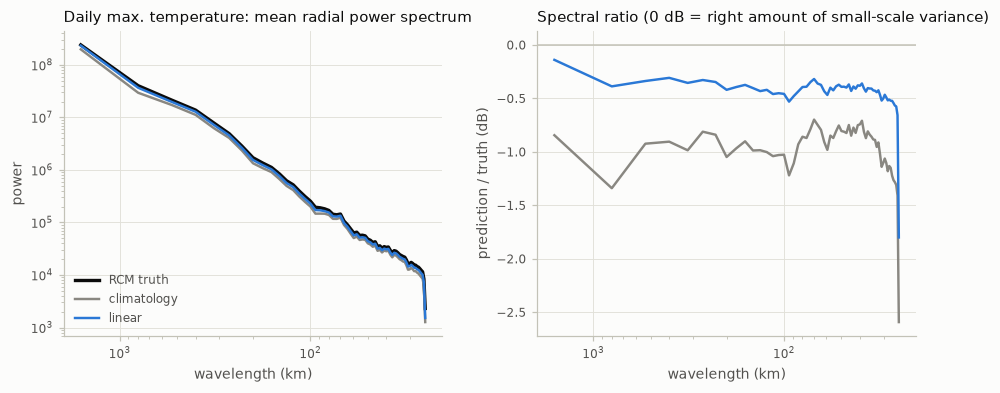

In [11]:
for var in EXP.variables:
    P.fig_spectra(D, var, COLORS, save=save(f"spectra_{var}_{SPLIT}"))

## 7. Distributions and extremes

Left: density over all days and grid points (log scale; pr dry-day fraction in the legend). Right: pooled
quantiles 0.5 … 0.9999 against the truth; points below the 1:1 line in the upper tail mean extremes are
underestimated.

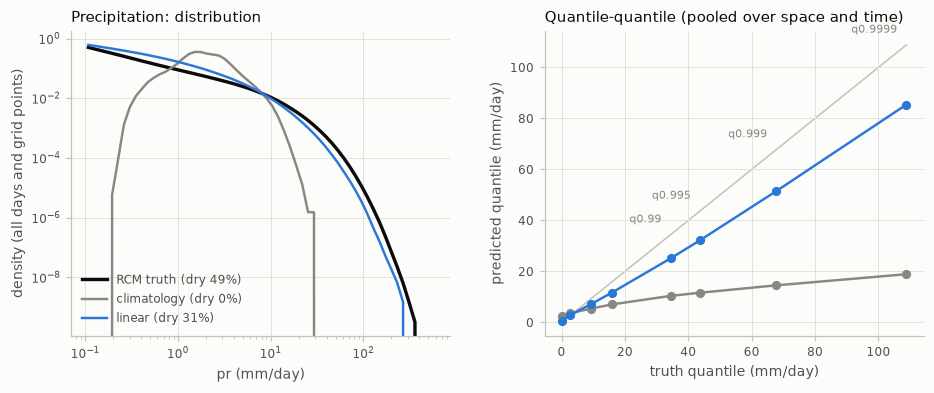

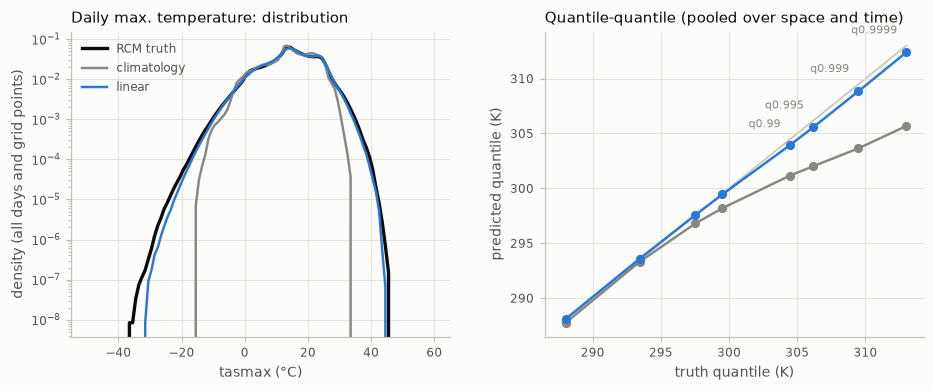

In [12]:
for var in EXP.variables:
    P.fig_distributions(D, var, COLORS, save=save(f"distributions_{var}_{SPLIT}"))

## 8. Seasonal cycle of the bias
Domain-mean bias per calendar month.

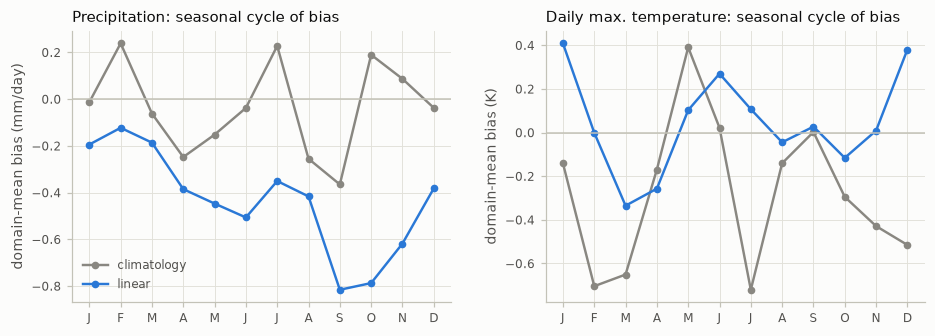

In [13]:
P.fig_seasonal_bias(D, COLORS, EXP.variables, save=save(f"seasonal_{SPLIT}"));

## 9. Climate change signal

Change of the time mean from the historical test period to the future split (precipitation in %, temperature in K):
truth and each run (top), error of each run's change (bottom). ESD models are trained on 1961–1980 only, so this is
an extrapolation test: a model that just reproduces the training climatology shows no warming at all.

,"pr change (%, domain mean)","tasmax change (K, domain mean)"
model,,
RCM truth,+2.13,+2.97
climatology,-0.00,+0.00
linear,+4.41,+2.95


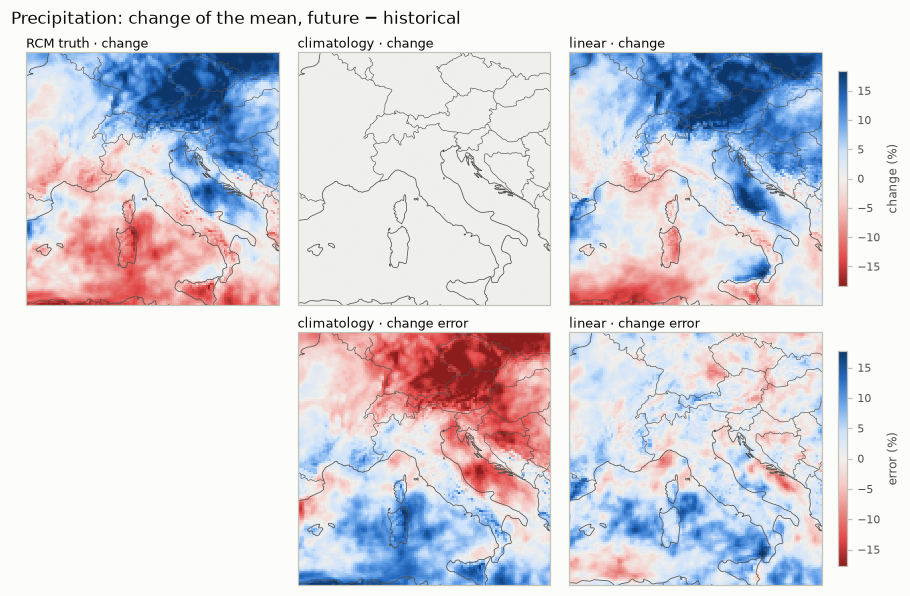

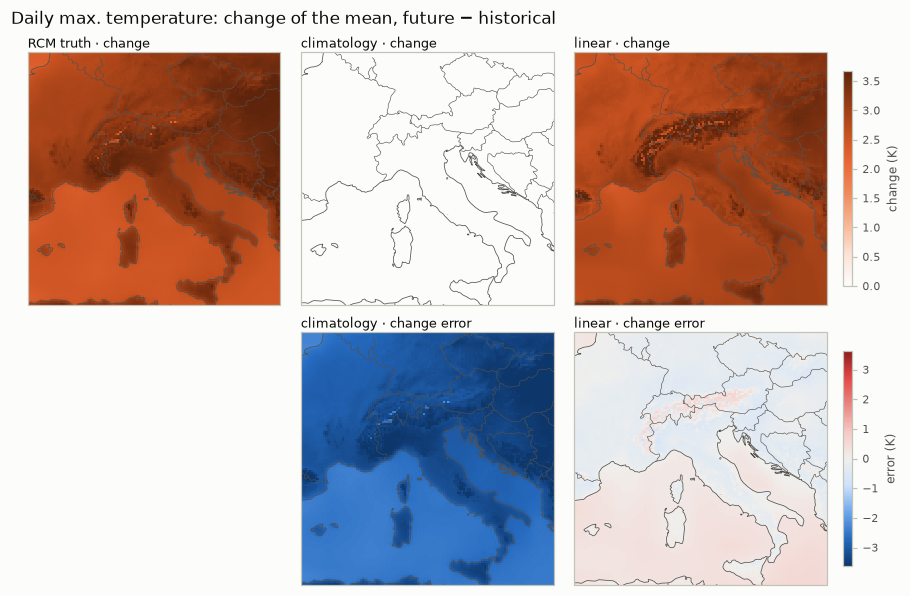

In [14]:
DF = {r: results.load_diagnostics(EXP, r, FUTURE) for r in RUNS}
for var in EXP.variables:
    P.fig_change_maps(D, DF, var, MG, save=save(f"change_{var}"))

rows = []
for var in EXP.variables:
    th, tf = float(D[RUNS[0]][f"{var}_mean_true"].mean()), float(DF[RUNS[0]][f"{var}_mean_true"].mean())
    for name, h, f in [("RCM truth", th, tf)] + [
            (r, th + float(D[r][f"{var}_bias_mean"].mean()), tf + float(DF[r][f"{var}_bias_mean"].mean()))
            for r in RUNS]:
        rows.append({"variable": var, "model": name,
                     "change": 100 * (f - h) / h if var == "pr" else f - h})
change = pd.DataFrame(rows).pivot(index="model", columns="variable", values="change")
change.columns = [f"{v} change ({'%' if v == 'pr' else 'K'}, domain mean)" for v in change.columns]
change.style.format("{:+.2f}")

## 10. Ensemble calibration

Only for stochastic runs (more than one member): rank histograms (flat = calibrated, U-shape = under-dispersive,
dome = over-dispersive), spread/skill ratio and CRPS.

In [15]:
stoch = [r for r in RUNS if scores[(scores.run == r)].n_members.max() > 1]
if not stoch:
    print("No stochastic runs evaluated yet.")
else:
    P.fig_rank_histograms({r: D[r] for r in stoch}, COLORS, EXP.variables, save=save(f"rank_hist_{SPLIT}"))
    s = scores[(scores.split == SPLIT) & scores.run.isin(stoch) & scores.metric.isin(["CRPS", "Spread/skill"])]
    display(s.pivot_table(index="run", columns=["variable", "metric"], values="value").style.format(fmt))

No stochastic runs evaluated yet.


---
**Adding a model.** Implement a `Downscaler` subclass in `src/dslab/models/` (see `linear.py`), register it,
add `configs/models/<name>.yaml`, then `dslab fit`, `dslab predict`, `dslab evaluate` (or a batch job). It will
appear here automatically. Pin its colour with `P.RUN_COLORS["<name>"] = P.SERIES[k]` before `run_colors`.